In [1]:
# Konfigurasi path: otomatis menyesuaikan Google Colab atau lokal
# Lokal: letakkan 5 file CSV asli di data/raw/ (lihat data/README.md)
# Demo cepat: jalankan dengan  DATA_DIR=data/sample  (angka akan berbeda karena hanya sampel)
import os
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/dibimbing/final_project/dataset')
    PROCESSED_DIR = Path('.')
except ImportError:
    DATA_DIR = Path(os.environ.get('DATA_DIR', '../data/raw'))
    PROCESSED_DIR = Path('../data/processed')

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


Mounted at /content/drive


# Final Project: Profit Leakage Analysis — E-Commerce Sales & Customer Analytics

**Problem Statement:** Perusahaan terlihat tumbuh dari sisi revenue, tapi profitabilitasnya tidak konsisten — bahkan ada transaksi yang justru rugi. Di mana kebocoran profit ini terjadi, dan apa yang bisa dilakukan untuk memperbaikinya?

**Dataset:** E-Commerce Sales & Customer Analytics (5 file: order-level, order items, product catalog, customer master, dataset statistics)

**Metodologi:** CRISP-DM style — Business Understanding → Data Understanding → Data Preparation → EDA / Hypothesis Testing → Root Cause Synthesis → Recommendation


## 1. Business Understanding

Dari problem statement, diturunkan jadi 3 pertanyaan analisis:

1. **Kapan** ketidakkonsistenan profit terjadi — acak, atau ada pola waktu tertentu?
2. **Di mana** kebocoran terkonsentrasi — kategori produk, channel, region, atau tipe customer tertentu?
3. **Apa mekanismenya** — komponen biaya/diskon mana yang membuat transaksi bisa sampai rugi?

**Hipotesis yang diuji:**
- **H1** — Penurunan profitabilitas berkaitan dengan periode/musim tertentu, bukan tren acak
- **H2** — Kebocoran tidak merata, terkonsentrasi pada kategori/channel/region tertentu
- **H3** — Diskon/promosi adalah komponen biaya utama penggerus profit, dibanding komponen lain (shipping, tax)
- **H4** — Ada interaksi antara volume order (quantity) dengan besaran diskon yang memperparah kerugian

**Definisi metrik:**
- Profitabilitas → `profit` (nominal) & `profit_margin_percentage` (relatif)
- "Tidak konsisten" → volatilitas margin antar waktu
- "Rugi" → transaksi dengan `profit < 0`


## 2. Data Understanding

| File | Granularitas | Peran |
|---|---|---|
| `ecommerce_sales_customer_analytics_150k.csv` | 1 baris = 1 order (138,116 baris) | tabel utama, sudah agregat per order |
| `order_items.csv` | 1 baris = 1 produk dalam 1 order (397,569 baris) | detail item-level |
| `product_catalog.csv` | 1 baris = 1 produk (1,175 baris) | master kategori, brand |
| `customer_master.csv` | 1 baris = 1 customer (25,000 baris) | master demografi customer |
| `dataset_statistics.csv` | ringkasan | angka resmi untuk validasi |

**Relasi:** `order_items.order_id` → tabel utama | `order_items.product_id` → `product_catalog.product_id` | tabel utama `.customer_id` → `customer_master.customer_id`


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 60)

orders_raw = pd.read_csv(DATA_DIR / 'ecommerce_sales_customer_analytics_150k.csv', parse_dates=['order_date'])
items_raw = pd.read_csv(DATA_DIR / 'order_items.csv')
catalog = pd.read_csv(DATA_DIR / 'product_catalog.csv')
customer = pd.read_csv(DATA_DIR / 'customer_master.csv')
stats = pd.read_csv(DATA_DIR / 'dataset_statistics.csv')

print("Orders:", orders_raw.shape, "| Items:", items_raw.shape, "| Catalog:", catalog.shape, "| Customer:", customer.shape)


Orders: (138116, 46) | Items: (397569, 12) | Catalog: (1175, 9) | Customer: (25000, 11)


### Data quality check

Integritas referensial (order_id, product_id, customer_id) bersih — tidak ada baris orphan. Tidak ada baris duplikat penuh.

**Temuan penting:** total `profit` di `order_items` ($82.7 juta) tidak sama persis dengan total `profit` di tabel order-level ($76.1 juta) — selisih ~$6.5 juta (begitu juga `gross_sales`). Setelah dicek ke `dataset_statistics.csv`, angka **tabel order-level yang jadi acuan resmi** (net_sales-nya persis sama: $177,134,263.74).

**Keputusan:** tabel order-level dipakai sebagai *source of truth* untuk semua angka agregat (trend, total profit). `order_items` + `product_catalog` hanya dipakai untuk breakdown per kategori (info yang tidak ada di tabel utama).

Missing value di `campaign_name` (60%) dan `coupon_code` (80%) itu wajar — artinya order tanpa campaign/kupon, bukan data rusak.


In [ ]:
# Validasi ground truth
print("Net sales (order-level):", orders_raw['net_sales'].sum())
print("dataset_statistics Total Revenue:", stats[stats.iloc[:,0].astype(str).str.contains('Revenue', case=False, na=False)] if stats.shape[1]>1 else stats.to_string())


Net sales (order-level): 177134263.73999998
dataset_statistics Total Revenue: Empty DataFrame
Columns: [Total Transactions, Total Columns, Total Customers, Total Products Used, Date Range, Total Revenue, Total Profit, Average Order Value, Average Rating, Return Rate, Cancellation Rate]
Index: []


## 3. Data Preparation

**Keputusan scope:** analisis kebocoran profit hanya memakai order berstatus **`Completed`** dan **`Returned`**.
- `Cancelled` dikeluarkan — order tidak pernah benar-benar terealisasi, walau ada angka profit di data, tidak merepresentasikan kebocoran nyata
- `Pending` dikeluarkan — outcome belum jelas
- `Returned` tetap dipakai — biaya fulfillment sudah keluar duluan, retur adalah salah satu bentuk kebocoran profit yang nyata

Populasi akhir: **123,021 dari 138,116 order (89.1%)**.


In [ ]:
df = orders_raw[orders_raw['order_status'].isin(['Completed', 'Returned'])].copy()
print(f"Order sebelum filter: {len(orders_raw):,} -> sesudah filter: {len(df):,}")

# Kolom turunan
df['month'] = df['order_date'].dt.to_period('M').astype(str)
df['month_num'] = df['order_date'].dt.month

# Deteksi 2 periode musiman (ditemukan di EDA awal H1 -> lihat pola grafik margin bulanan)
df['season'] = 'Normal'
df.loc[df['month_num'].isin([11, 12]), 'season'] = 'Peak (Nov-Des)'
df.loc[df['month_num'] == 7, 'season'] = 'Mid-year (Jul)'

df['discount_pct_of_gross'] = (df['discount_amount'] / df['gross_sales'] * 100).round(2)
df['is_loss'] = df['profit'] < 0
df['qty_bucket'] = pd.cut(df['quantity'], bins=[0, 2, 4, 6, 8, 100], labels=['1-2', '3-4', '5-6', '7-8', '9+'])

df.to_csv(PROCESSED_DIR / 'orders_prepped.csv', index=False)
df.head()


Order sebelum filter: 138,116 -> sesudah filter: 123,021


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_days,estimated_delivery_days,delivery_status,return_status,return_reason,customer_rating,review_sentiment,customer_review,marketing_channel,campaign_name,coupon_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count,month,month_num,season,discount_pct_of_gross,is_loss,qty_bucket
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,86040,Digital Wallet,Paid,USD,Standard,WH-003,3.0,3.0,On Time,NaN,NaN,3.5,Positive,Satisfied with the purchase.,Direct,Default_Campaign,NaN,94,44,5,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11,2023-11,11,Peak (Nov-Des),35.39,False,5-6
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,62538,Debit Card,Pending,EUR,Economy,WH-005,10.0,10.0,On Time,NaN,NaN,3.6,Positive,Good value for money.,Direct,Default_Campaign,NaN,201,171,8,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11,2025-12,12,Peak (Nov-Des),46.30,True,7-8
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,Loyal,Singletonhaven,New York,USA,East,19993,Cash on Delivery,Paid,USD,Express,WH-015,3.0,3.0,On Time,NaN,NaN,4.3,Positive,Good product. Works as expected.,YouTube,NaN,NaN,46,16,5,522.81,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6,2021-07,7,Mid-year (Jul),18.61,False,5-6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,Loyal,Wigginsstad,North Carolina,USA,South,66329,Debit Card,Paid,USD,Express,WH-010,2.0,2.0,On Time,NaN,NaN,3.5,Positive,Satisfied with the purchase.,Email Marketing,NaN,NaN,54,10,2,544.62,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7,2023-01,1,Normal,9.79,False,1-2
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,Loyal,New Michaelton,Gujarat,India,West,77306,Digital Wallet,Paid,INR,Standard,WH-013,6.0,5.0,Delayed,NaN,NaN,3.0,Neutral,Mixed feelings about this purchase.,Direct,NaN,NaN,278,147,6,2474.52,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8,2022-05,5,Normal,5.40,False,5-6


In [ ]:
# Dataset item-level (khusus untuk breakdown kategori di H2)
items = items_raw.merge(catalog[['product_id', 'product_category', 'product_subcategory', 'brand']],
                         on='product_id', how='left')
items = items.merge(df[['order_id', 'season', 'month']], on='order_id', how='inner')  # samain scope
items['discount_pct_of_gross'] = (items['discount_amount'] / items['gross_sales'] * 100).round(2)
items['is_loss'] = items['profit'] < 0

items.to_csv(PROCESSED_DIR / 'items_prepped.csv', index=False)
print("Items prepped:", items.shape)


Items prepped: (354237, 19)


## 4. EDA & Hypothesis Testing

### H1 — Pola Waktu

Plot margin bulanan menunjukkan pola yang **berulang identik setiap tahun** (2021-2025) — bukan tren acak. Ada 2 dip musiman:
1. Dip **dalam** (~31-33%) — selalu Nov-Des
2. Dip **sedang** (~38-40%) — selalu Juli

**H1 terkonfirmasi**, dengan revisi: musiman ganda, bukan tunggal.


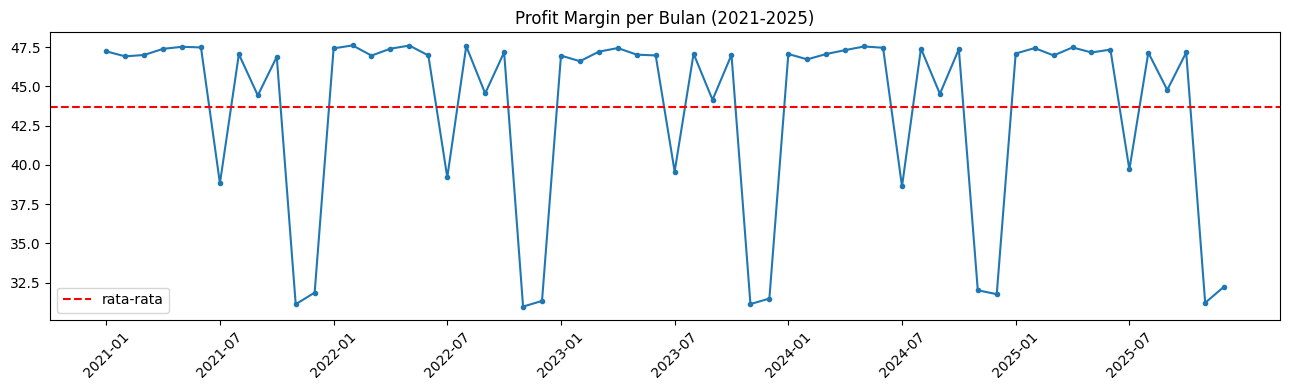

            revenue      profit  margin_%
month                                    
2022-11  3950276.56  1223410.40     30.97
2021-11  3759577.87  1169945.25     31.12
2023-11  3837249.99  1194423.14     31.13
2025-11  3866266.73  1206606.50     31.21
2022-12  4103621.67  1285583.47     31.33
2023-12  4203763.23  1323287.90     31.48
2024-12  3986423.32  1265957.30     31.76
2021-12  4366939.44  1391422.56     31.86
2024-11  3838822.03  1228625.56     32.01
2025-12  4056276.42  1307796.27     32.24


In [ ]:
monthly = df.groupby('month').apply(lambda x: pd.Series({
    'revenue': x['net_sales'].sum(),
    'profit': x['profit'].sum(),
}), include_groups=False)
monthly['margin_%'] = (monthly['profit'] / monthly['revenue'] * 100).round(2)

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(range(len(monthly)), monthly['margin_%'], marker='o', markersize=3)
ax.axhline(monthly['margin_%'].mean(), color='red', linestyle='--', label='rata-rata')
ax.set_xticks(range(0, len(monthly), 6))
ax.set_xticklabels([monthly.index[i] for i in range(0, len(monthly), 6)], rotation=45)
ax.set_title('Profit Margin per Bulan (2021-2025)')
ax.legend()
plt.tight_layout()
plt.show()

print(monthly.sort_values('margin_%').head(10))


### H2 — Konsentrasi (Kategori, Channel, Region)

**Channel & region:** penurunan margin saat peak season **relatif seragam** di semua channel (~22-23 poin) dan semua region (~22-24 poin) — bukan terkonsentrasi di channel/region tertentu.

**Kategori produk:** penurunan absolut (poin persentase) juga relatif seragam antar kategori (~20-22 poin). Tapi karena kategori seperti **Electronics, Automotive, Jewelry, Home Appliances** punya margin dasar yang sudah tipis (~38-45% normal), penurunan yang sama membuat mereka jatuh sampai mendekati titik impas (17-23% saat peak), sementara kategori margin tebal (Grocery, Books & Media) masih relatif aman.

**Kesimpulan H2 (direvisi):** dampaknya broad-based (bukan menyasar segmen tertentu secara spesifik), tapi konsekuensinya terkonsentrasi di kategori bermargin tipis karena mereka tidak punya bantalan margin yang cukup untuk menyerap diskon musiman yang sama besarnya.


In [ ]:
cat_summary = items.groupby(['product_category', 'season'])[['gross_sales', 'profit']].sum().reset_index()
cat_summary['margin_%'] = (cat_summary['profit'] / cat_summary['gross_sales'] * 100).round(2)
pivot = cat_summary.pivot(index='product_category', columns='season', values='margin_%')
pivot['drop_peak_vs_normal'] = (pivot['Normal'] - pivot['Peak (Nov-Des)']).round(2)
print(pivot.sort_values('drop_peak_vs_normal', ascending=False))

for dim in ['sales_channel', 'region']:
    g = df.groupby([dim, 'season'])[['gross_sales', 'profit']].sum().reset_index()
    g['margin_%'] = (g['profit'] / g['gross_sales'] * 100).round(2)
    p = g.pivot(index=dim, columns='season', values='margin_%')
    p['drop_peak_vs_normal'] = (p['Normal'] - p['Peak (Nov-Des)']).round(2)
    print(f"\n=== {dim} ===")
    print(p.sort_values('drop_peak_vs_normal', ascending=False))


season                  Mid-year (Jul)  Normal  Peak (Nov-Des)  drop_peak_vs_normal
product_category                                                                   
Baby & Kids                      40.84   53.25           31.28                21.97
Sports & Outdoors                36.93   49.24           27.63                21.61
Pet Supplies                     42.71   54.64           33.09                21.55
Office Supplies                  42.64   55.00           33.51                21.49
Grocery                          48.49   61.01           39.54                21.47
Home Appliances                  32.83   44.73           23.33                21.40
Health & Wellness                37.42   49.87           28.53                21.34
Beauty & Personal Care           44.82   56.79           35.51                21.28
Books & Media                    46.00   58.56           37.34                21.22
Jewelry                          31.76   43.99           22.83              

### H3 — Komponen Biaya

Membandingkan diskon, ongkir, dan pajak sebagai % dari gross sales per musim:

| Season | Diskon % | Ongkir % | Pajak % | Margin % |
|---|---|---|---|---|
| Normal | 10.95% | 1.79% | 9.60% | 46.90% |
| Mid-year (Jul) | 22.76% | 1.41% | 8.29% | 39.19% |
| Peak (Nov-Des) | **31.49%** | 1.29% | 7.35% | 31.52% |

Diskon **melonjak hampir 3x lipat** (10.95% → 31.49%), sementara ongkir dan pajak justru **turun** sebagai persentase gross sales. **H3 terkonfirmasi tegas** — diskon adalah satu-satunya komponen biaya yang menjadi pendorong penurunan margin musiman.


In [ ]:
cost_cols = ['discount_amount', 'shipping_cost', 'tax_amount']
rows = []
for season, g in df.groupby('season'):
    row = {'season': season, 'gross_sales': g['gross_sales'].sum()}
    for c in cost_cols:
        row[f'{c}_pct'] = round(g[c].sum() / g['gross_sales'].sum() * 100, 2)
    row['margin_%'] = round(g['profit'].sum() / g['net_sales'].sum() * 100, 2)
    rows.append(row)
h3 = pd.DataFrame(rows).set_index('season').reindex(['Normal', 'Mid-year (Jul)', 'Peak (Nov-Des)'])
print(h3)


                 gross_sales  discount_amount_pct  shipping_cost_pct  tax_amount_pct  margin_%
season                                                                                        
Normal          1.043460e+08                10.95               1.79            9.60     46.90
Mid-year (Jul)  1.448238e+07                22.76               1.41            8.29     39.19
Peak (Nov-Des)  5.180721e+07                31.49               1.29            7.35     31.52


### H4 — Interaksi Quantity x Diskon

Saat peak season, semakin besar quantity per order, semakin besar juga diskon rata-rata yang diberikan (18.7% untuk 1-2 item → 32.9% untuk 9+ item), dan tingkat transaksi rugi ikut naik.

Korelasi quantity vs discount%: **0.044 (Normal) → 0.265 (Peak)** — hampir 6x lebih kuat. Ini indikasi kuat adanya **tiered/bulk discount** yang di-stack dengan promo musiman tanpa cap yang memadai.

**H4 terkonfirmasi.**

**Profil transaksi rugi:** dari 1,229 transaksi rugi di populasi ini, **98.9% terjadi di Peak (Nov-Des)**. Rata-rata diskon pada transaksi rugi adalah **51.7%** dari gross sales, dibanding **15.7%** pada transaksi untung.


In [ ]:
peak = df[df['season'] == 'Peak (Nov-Des)']
h4 = peak.groupby('qty_bucket', observed=True).agg(
    avg_discount_pct=('discount_pct_of_gross', 'mean'),
    avg_margin=('profit_margin_percentage', 'mean'),
    loss_rate=('is_loss', 'mean'),
    n=('order_id', 'count')
).round(3)
print(h4)

corr_peak = peak['quantity'].corr(peak['discount_pct_of_gross'])
corr_normal = df[df['season']=='Normal']['quantity'].corr(df[df['season']=='Normal']['discount_pct_of_gross'])
print(f"\nKorelasi qty vs discount%  ->  Peak: {corr_peak:.3f}  |  Normal: {corr_normal:.3f}")

loss = df[df['is_loss']]
print(f"\nTransaksi rugi: {len(loss)} dari {len(df)} ({len(loss)/len(df)*100:.2f}%)")
print("Distribusi musim:\n", loss['season'].value_counts(normalize=True).round(3))
print(f"\nRata-rata diskon% -> rugi: {loss['discount_pct_of_gross'].mean():.2f}% | untung: {df[~df['is_loss']]['discount_pct_of_gross'].mean():.2f}%")


            avg_discount_pct  avg_margin  loss_rate     n
qty_bucket                                               
1-2                   18.676      42.864      0.022  3256
3-4                   27.466      35.874      0.051  5683
5-6                   29.145      34.067      0.044  5856
7-8                   30.855      32.463      0.045  5253
9+                    32.892      30.610      0.036  9880

Korelasi qty vs discount%  ->  Peak: 0.265  |  Normal: 0.044

Transaksi rugi: 1229 dari 123021 (1.00%)
Distribusi musim:
 season
Peak (Nov-Des)    0.989
Mid-year (Jul)    0.011
Name: proportion, dtype: float64

Rata-rata diskon% -> rugi: 51.72% | untung: 15.67%


## 5. Root Cause Synthesis

Merangkai semua hipotesis yang sudah terkonfirmasi jadi satu narasi akar masalah:

1. Revenue tahunan sebenarnya **relatif flat** (~$35-38 juta/tahun) — pertumbuhan yang terlihat sebenarnya adalah **lonjakan volume order musiman** (Nov-Des dan Juli), bukan pertumbuhan bisnis yang genuine.
2. Di 2 periode musiman ini, tim (marketing/promo) menaikkan **diskon hampir 3x lipat** dari kondisi normal — dan diskon di-*stack* semakin dalam untuk order dengan quantity besar, tanpa margin floor/cap yang memadai.
3. Komponen biaya lain (ongkir, pajak) tidak berkontribusi pada masalah ini — bahkan proporsinya turun.
4. Dampak diskon berlebih ini menyebar merata ke semua channel/region, tapi **paling parah dirasakan kategori bermargin tipis** (Electronics, Automotive, Jewelry, Home Appliances) karena mereka tidak punya bantalan margin.
5. Akibatnya: 98.9% dari seluruh transaksi rugi perusahaan terjadi hanya dalam 2 bulan (Nov-Des) setiap tahun, berulang selama 5 tahun tanpa perbaikan.

**Kesimpulan:** kebocoran profit bukan masalah operasional harian yang tersebar acak, melainkan **kegagalan tata kelola diskon musiman** yang sistemik dan berulang.


## 6. Simulasi Dampak Perbaikan

Simulasi: bila diskon di-cap maksimal 20% khusus selama peak season (Nov-Des), berapa potensi profit yang bisa diselamatkan?


In [ ]:
cap = 20.0
sim = df.copy()
mask = (sim['season'] == 'Peak (Nov-Des)') & (sim['discount_pct_of_gross'] > cap)
new_discount = sim.loc[mask, 'gross_sales'] * cap / 100
delta_discount = sim.loc[mask, 'discount_amount'] - new_discount
sim_profit = sim['profit'].copy()
sim_profit.loc[mask] = sim_profit.loc[mask] + delta_discount

actual_profit = df['profit'].sum()
print(f"Profit aktual: ${actual_profit:,.2f}")
print(f"Profit simulasi (cap diskon {cap}% saat peak): ${sim_profit.sum():,.2f}")
print(f"Potensi kenaikan profit: ${sim_profit.sum()-actual_profit:,.2f} ({(sim_profit.sum()/actual_profit-1)*100:.2f}%)")
print(f"Transaksi rugi: {(df['profit']<0).sum()} -> {(sim_profit<0).sum()} setelah simulasi")


Profit aktual: $66,684,066.43
Profit simulasi (cap diskon 20.0% saat peak): $73,502,560.28
Potensi kenaikan profit: $6,818,493.85 (10.23%)
Transaksi rugi: 1229 -> 13 setelah simulasi


**Hasil:** cap diskon 20% saat peak season berpotensi menaikkan total profit periode 2021-2025 sebesar **~10.2% (~$6.8 juta, atau rata-rata ~$1.4 juta per tahun)** dan menghilangkan **hampir seluruh transaksi rugi** (dari 1,229 menjadi hanya 13). Ini angka konservatif karena hanya menyesuaikan diskon yang melebihi cap, tanpa mengasumsikan penurunan volume order.


## 7. Rekomendasi

1. **Margin floor rule** pada sistem promo — diskon otomatis dibatasi agar net margin per transaksi tidak jatuh di bawah threshold (misal 20%), terutama untuk kategori bermargin tipis (Electronics, Automotive, Jewelry, Home Appliances).
2. **Review struktur tiered/bulk discount** — hindari diskon yang terus naik linear tanpa batas atas seiring quantity, apalagi saat ditumpuk dengan promo musiman.
3. **Strategi berbeda untuk kategori margin tipis** saat kampanye besar — misal diskon nominal capped (bukan persentase), bundling, atau negosiasi margin protection dengan supplier saat periode promo.
4. **Audit per campaign_name** khusus periode Nov-Des dan Juli untuk mengidentifikasi kampanye spesifik mana yang paling menggerus margin.
5. **Dashboard margin real-time** selama kampanye berjalan — supaya tim bisa intervensi saat kampanye masih berjalan, bukan baru sadar setelah bulan berakhir.

### Ringkasan Eksekutif

Dari total 123,021 transaksi (2021-2025), **1,229 transaksi (1.0%) mengalami kerugian**, dan **98.9% dari transaksi rugi ini terjadi khusus pada bulan November-Desember** setiap tahun. Akar masalahnya adalah lonjakan diskon musiman (dari ~11% menjadi ~31% dari gross sales) yang tidak dibatasi, dan efeknya paling parah dirasakan kategori produk bermargin tipis. Simulasi menunjukkan potensi penyelamatan profit sebesar **~$6.8 juta (10.2%) selama 2021-2025, atau rata-rata ~$1.4 juta per tahun** apabila diskon musiman dibatasi maksimal 20%.
